## Analysis after dimensionality reduction

After multiple rounds of data cleaning, the improvement in the baseline model's silhouette score reached a bottleneck. To further mitigate the "curse of dimensionality" inherent in high-dimensional sparse features and to enhance the model's sensitivity to core semantics, I explored the integration of dimensionality reduction techniques. Specifically, I applied Latent Semantic Analysis (LSA via TruncatedSVD) combined with L2 normalization for the BoW and TF-IDF models, and Principal Component Analysis (PCA) with L2 normalization for the SBERT dense vectors.

Experimental results demonstrated that compressing the SBERT embeddings from 384 to 80 dimensions yielded a significant improvement in the clustering silhouette score. However, the PCA output revealed that this reduction process resulted in a loss of approximately 15% of the explained variance. Given the context of our customer support ticket data, it remains uncertain whether these 15% marginal features contain critical, minority-class customer complaints. Therefore, to prioritize model robustness and preserve information integrity, this aggressive dimensionality reduction approach was excluded from our primary analytical pipeline.

Additionally, I tried UMAP as a non-linear dimensionality reduction technique. Although the UMAP-transformed data exhibited an artificially inflated and dramatic surge in silhouette scores, I ultimately chose to discard this method. The fundamental reason is that UMAP forcibly distorts the global topological structure to cluster local neighbors together, which inherently destroys the authentic Euclidean distance metrics. Calculating distance-dependent silhouette scores within this distorted space generates a severe "mathematical illusion" akin to overfitting, rendering the results entirely meaningless for guiding real-world business classification.

This notebook compares each dimensionality-reduction approach against its original representation, using the same data, labels and clustering functions as `ClusterningAnalysis.ipynb`.

**Prerequisite:** run `03_text_representation/Text-Preprocessing.ipynb` first, so the BoW, TF-IDF and SBERT representations exist in `data/processed/`.

The custom stop-word list is already applied during preprocessing, so the BoW and TF-IDF inputs here already include it.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.decomposition import TruncatedSVD, PCA
import umap

In [2]:
def find_root():
    """Walk up from the current folder to the project root (the folder containing src/ and notebooks/)."""
    cwd = Path.cwd()
    for path in [cwd] + list(cwd.parents):
        if (path / "src").is_dir() and (path / "notebooks").is_dir():
            return path
    return cwd

root_path = find_root().resolve()
if str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))
os.chdir(root_path)

figures_dir = root_path / 'reports' / 'figures'
tables_dir = root_path / 'reports' / 'tables'
figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)
print('Project root found:', (root_path / 'src').is_dir())

Project root found: True


In [3]:
from src.clustering.KMeans import run_kmeans
from src.clustering.Hac import run_hac
from src.evaluation.ClusterEvaluation import evaluate_clusters

### Load the representations and the reference labels

In [4]:
data_dir = root_path / 'data' / 'processed'
df = pd.read_csv(root_path / 'data' / 'raw' / 'customer_support_tickets.csv')

X_bow = sp.load_npz(data_dir / 'bow_vectors.npz')
X_tfidf = sp.load_npz(data_dir / 'tfidf_vectors.npz')
X_sbert = np.load(data_dir / 'sbert_embeddings.npy')

le = LabelEncoder()
y_type = le.fit_transform(df['Ticket Type'])
y_subj = le.fit_transform(df['Ticket Subject'])

print('BoW    :', X_bow.shape)
print('TF-IDF :', X_tfidf.shape)
print('SBERT  :', X_sbert.shape)

BoW    : (8469, 5000)
TF-IDF : (8469, 3642)
SBERT  : (8469, 384)


### Clustering sweep

Same procedure as the main clustering notebook: K-Means and HAC for each k, scored with the silhouette score and with ARI / NMI against the ticket type and ticket subject.

In [5]:
K_RANGE = range(2, 11)

def clustering_sweep(X, name, metric, k_range=K_RANGE):
    rows = []
    for k in k_range:
        for algo, labels in (('KMeans', run_kmeans(X=X, k=k)), ('HAC', run_hac(X=X, k=k))):
            sil, ari_type, nmi_type = evaluate_clusters(X=X, cluster_labels=labels, true_labels=y_type, metric=metric)
            _, ari_subj, nmi_subj = evaluate_clusters(X=X, cluster_labels=labels, true_labels=y_subj, metric=metric)
            rows.append({'Representation': name, 'Algorithm': algo, 'k': k, 'Silhouette': sil,
                         'ARI (Type)': ari_type, 'NMI (Type)': nmi_type,
                         'ARI (Subject)': ari_subj, 'NMI (Subject)': nmi_subj})
    return pd.DataFrame(rows)

### Baselines

The original representations, scored with cosine distance as in the main clustering notebook.

In [6]:
baseline = pd.concat([
    clustering_sweep(X_bow, 'BoW', metric='cosine'),
    clustering_sweep(X_tfidf, 'TF-IDF', metric='cosine'),
    clustering_sweep(X_sbert, 'SBERT', metric='cosine'),
], ignore_index=True)
baseline['Variant'] = 'Baseline'

### LSA & Normalization for BoW & TF-IDF

In [7]:
def optimize_sparse_matrix(X, name, n_components=80):
    """LSA (TruncatedSVD) followed by L2 normalisation."""
    svd = TruncatedSVD(n_components=n_components, random_state=42)
    X_lsa = svd.fit_transform(X)
    print(f'{name}: LSA explained variance ({n_components} components): {svd.explained_variance_ratio_.sum():.4f}')
    return normalize(X_lsa, norm='l2')

X_bow_improved = optimize_sparse_matrix(X_bow, 'BoW')
X_tfidf_improved = optimize_sparse_matrix(X_tfidf, 'TF-IDF')

BoW: LSA explained variance (80 components): 0.7357


TF-IDF: LSA explained variance (80 components): 0.5722


### PCA + Normalization for SBERT

In [8]:
# L2 normalisation makes Euclidean distance equivalent to cosine similarity
X_sbert_norm = normalize(X_sbert, norm='l2')

# PCA from 384 to 80 dimensions
pca_opt = PCA(n_components=80, random_state=42)
X_sbert_improved = pca_opt.fit_transform(X_sbert_norm)
print(f'PCA explained variance ratio (80 components): {pca_opt.explained_variance_ratio_.sum():.4f}')

PCA explained variance ratio (80 components): 0.8405


### UMAP for SBERT

In [9]:
umap_reducer = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=10, metric='cosine', random_state=42)
X_sbert_umap = umap_reducer.fit_transform(X_sbert)
print('UMAP output:', X_sbert_umap.shape)

UMAP output: (8469, 10)


### Sweep the reduced representations

In [10]:
reduced = pd.concat([
    clustering_sweep(X_bow_improved, 'BoW', metric='euclidean').assign(Variant='LSA + L2'),
    clustering_sweep(X_tfidf_improved, 'TF-IDF', metric='euclidean').assign(Variant='LSA + L2'),
    clustering_sweep(X_sbert_improved, 'SBERT', metric='euclidean').assign(Variant='L2 + PCA'),
    clustering_sweep(X_sbert_umap, 'SBERT', metric='euclidean').assign(Variant='UMAP'),
], ignore_index=True)

results = pd.concat([baseline, reduced], ignore_index=True)
results.to_csv(tables_dir / 'dimensionality_reduction_sweep.csv', index=False)

### Comparison

Best silhouette score for each representation and variant, with the agreement (ARI / NMI) with the ticket labels at that k.

In [11]:
best = (results.loc[results.groupby(['Representation', 'Variant', 'Algorithm'])['Silhouette'].idxmax()]
        .sort_values(['Representation', 'Algorithm', 'Variant'])
        .reset_index(drop=True))
best.round(3)

,Representation,Algorithm,k,Silhouette,ARI (Type),NMI (Type),ARI (Subject),NMI (Subject),Variant
0,BoW,HAC,10,0.150,-0.0,0.001,-0.0,0.004,Baseline
1,BoW,HAC,10,0.182,-0.0,0.001,-0.0,0.004,LSA + L2
2,BoW,KMeans,9,0.170,-0.0,0.001,-0.0,0.003,Baseline
3,BoW,KMeans,10,0.223,0.0,0.001,-0.0,0.003,LSA + L2
4,SBERT,HAC,10,0.243,0.0,0.001,0.0,0.003,Baseline
5,SBERT,HAC,4,0.175,0.0,0.001,0.0,0.001,L2 + PCA
6,SBERT,HAC,10,0.588,0.0,0.001,0.0,0.003,UMAP
7,SBERT,KMeans,10,0.224,0.0,0.001,-0.0,0.003,Baseline
8,SBERT,KMeans,10,0.171,-0.0,0.001,-0.0,0.003,L2 + PCA
9,SBERT,KMeans,10,0.617,0.0,0.001,-0.0,0.003,UMAP


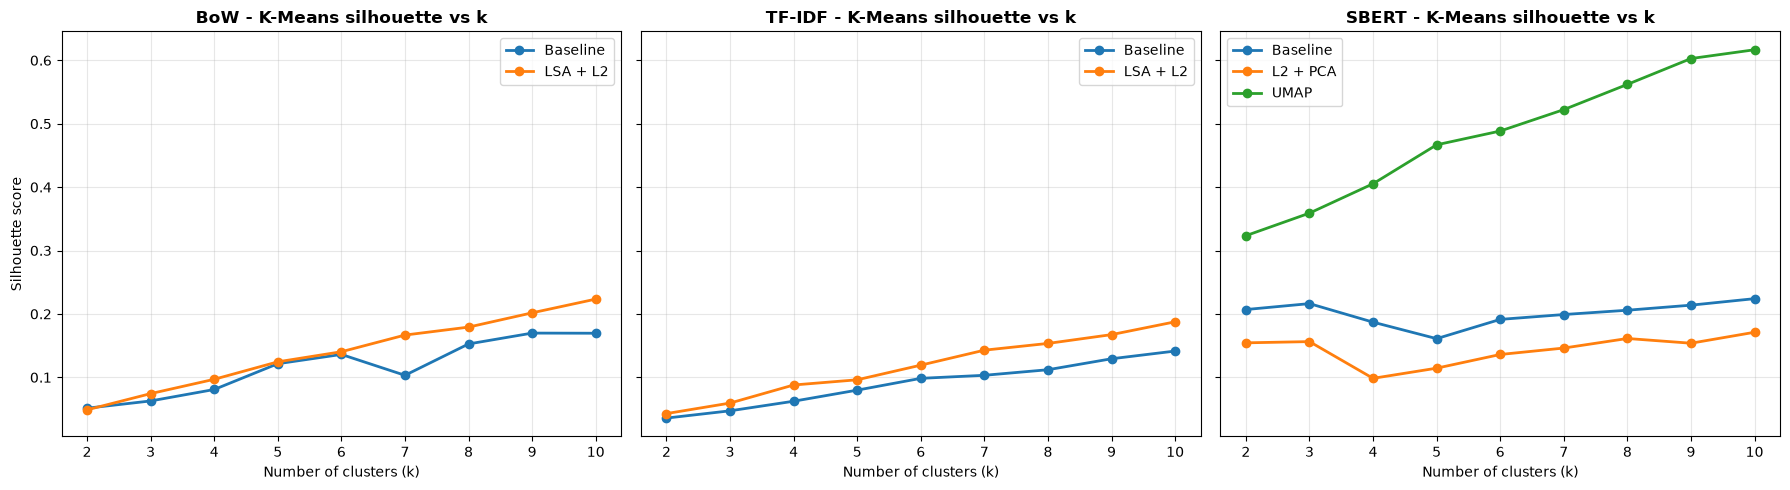

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, rep in zip(axes, ['BoW', 'TF-IDF', 'SBERT']):
    subset = results[(results['Representation'] == rep) & (results['Algorithm'] == 'KMeans')]
    for variant, group in subset.groupby('Variant'):
        ax.plot(group['k'], group['Silhouette'], marker='o', linewidth=2, label=variant)
    ax.set_title(f'{rep} - K-Means silhouette vs k', fontweight='bold')
    ax.set_xlabel('Number of clusters (k)')
    ax.grid(True, alpha=0.3)
    ax.legend()
axes[0].set_ylabel('Silhouette score')
plt.tight_layout()
plt.savefig(figures_dir / 'dimensionality_reduction_silhouette.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
# Agreement with the ticket labels at k = 5 (the number of ticket types), K-Means
k5 = results[(results['k'] == 5) & (results['Algorithm'] == 'KMeans')]
k5[['Representation', 'Variant', 'Silhouette', 'ARI (Type)', 'NMI (Type)', 'ARI (Subject)', 'NMI (Subject)']].round(3)

,Representation,Variant,Silhouette,ARI (Type),NMI (Type),ARI (Subject),NMI (Subject)
6,BoW,Baseline,0.121,-0.0,0.001,-0.0,0.002
24,TF-IDF,Baseline,0.080,-0.0,0.001,-0.0,0.002
42,SBERT,Baseline,0.161,0.0,0.001,0.0,0.002
60,BoW,LSA + L2,0.124,-0.0,0.001,-0.0,0.002
78,TF-IDF,LSA + L2,0.096,0.0,0.001,-0.0,0.002
96,SBERT,L2 + PCA,0.114,-0.0,0.000,-0.0,0.001
114,SBERT,UMAP,0.467,0.0,0.001,0.0,0.002


### Results on the current pipeline

Best silhouette score over k = 2–10 for each representation:

| Representation | Algorithm | Baseline | Reduced | Method |
|---|---|---|---|---|
| BoW | K-Means | 0.170 | 0.223 | LSA + L2 |
| BoW | HAC | 0.150 | 0.182 | LSA + L2 |
| TF-IDF | K-Means | 0.141 | 0.188 | LSA + L2 |
| TF-IDF | HAC | 0.087 | 0.149 | LSA + L2 |
| SBERT | K-Means | 0.224 | 0.171 | L2 + PCA (80) |
| SBERT | HAC | 0.243 | 0.175 | L2 + PCA (80) |
| SBERT | K-Means | 0.224 | 0.617 | UMAP (10) |
| SBERT | HAC | 0.243 | 0.588 | UMAP (10) |

- **LSA + L2** gives a modest silhouette improvement for both BoW and TF-IDF.
- **PCA** keeps 84.1% of the SBERT variance (about 16% is lost). On the current pipeline it *lowers* the silhouette score rather than improving it, which further supports leaving it out of the main pipeline.
- **UMAP** more than doubles the silhouette score, but agreement with the actual ticket labels does not change (ARI ≈ 0, NMI ≤ 0.004 for every variant). The higher score reflects UMAP's distortion of the distance space rather than better clusters, so it was also excluded.

*Silhouette scores are estimated on a random sample of 2,000 tickets, so values vary slightly (around ±0.01) between runs.*